# Whisper model comparison: accuracy, efficiency, and failure modes

This notebook compares four Whisper models and Wav2Vec2 on all 2,620 LibriSpeech `test-clean` recordings. It also evaluates them on a 300-recording sample of Earnings22 to test whether results from clean audiobook speech carry over to conversational financial calls.

The original 300-recording LibriSpeech sample is compared with the full test set to determine which conclusions from the smaller evaluation were reliable.

The main question is: **Which model provides the best balance of accuracy and speed across the two datasets, and what important errors does WER fail to show?**

The notebook compares model accuracy, published results, runtime and memory use, performance across different types of recordings and speakers, and serious errors such as missing or repeated phrases. It uses previously saved predictions and does not rerun the models.

In [1]:
from pathlib import Path
import re
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from jiwer import process_words, wer
from tqdm import TqdmWarning

warnings.filterwarnings('ignore', category=TqdmWarning)
from transformers import AutoTokenizer
from transformers.models.whisper.english_normalizer import BasicTextNormalizer

candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in candidates if (p / 'data' / 'manifest_n300.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter from the project root or notebooks/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.normalize import normalize_basic, normalize_custom, normalize_standard

RESULTS_DIR = PROJECT_ROOT / 'results'
MODEL_ORDER = ['tiny.en', 'base.en', 'small.en', 'medium.en']
FULL_MODEL_ORDER = ['tiny.en', 'base.en', 'wav2vec2-base', 'small.en', 'medium.en']
SEED = 42
result_files = {m: RESULTS_DIR / f'openai_whisper-{m}_manifest_n300.csv' for m in MODEL_ORDER}
missing = [p for p in result_files.values() if not p.exists()]
if missing:
    raise FileNotFoundError('Missing result files:\n' + '\n'.join(map(str, missing)))
frames = {m: pd.read_csv(p, dtype={'sample_id': str}).set_index('sample_id') for m, p in result_files.items()}
sample_ids = frames['tiny.en'].index
base_references = frames['tiny.en']['reference'].fillna('').reindex(sample_ids)
for model in MODEL_ORDER:
    if not frames[model].index.is_unique or set(frames[model].index) != set(sample_ids):
        raise ValueError(f'{model} sample IDs do not align')
    frames[model] = frames[model].reindex(sample_ids)
    if not frames[model]['reference'].fillna('').equals(base_references):
        raise ValueError(f'{model} references do not align')
full_result_files = {
    'tiny.en': RESULTS_DIR / 'openai_whisper-tiny.en_test_clean_full.csv',
    'base.en': RESULTS_DIR / 'openai_whisper-base.en_test_clean_full.csv',
    'wav2vec2-base': RESULTS_DIR / 'facebook_wav2vec2-base-960h_test_clean_full.csv',
    'small.en': RESULTS_DIR / 'openai_whisper-small.en_test_clean_full.csv',
    'medium.en': RESULTS_DIR / 'openai_whisper-medium.en_test_clean_full.csv',
}
missing_full = [p for p in full_result_files.values() if not p.exists()]
if missing_full:
    raise FileNotFoundError('Missing full-test result files:\n' + '\n'.join(map(str, missing_full)))
full_frames = {m: pd.read_csv(p, dtype={'sample_id': str}).set_index('sample_id') for m, p in full_result_files.items()}
full_sample_ids = full_frames['tiny.en'].index
full_base_references = full_frames['tiny.en']['reference'].fillna('').reindex(full_sample_ids)
for model in FULL_MODEL_ORDER:
    if len(full_frames[model]) != 2620 or set(full_frames[model].index) != set(full_sample_ids):
        raise ValueError(f'{model} full-test rows do not align')
    full_frames[model] = full_frames[model].reindex(full_sample_ids)
    if not full_frames[model]['reference'].fillna('').equals(full_base_references):
        raise ValueError(f'{model} full-test references do not align')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_colwidth', 120)
print(f'Python: {sys.executable}')
print(f'Project root: {PROJECT_ROOT}')
print('Loaded subset:', ', '.join(f'{m} ({len(frames[m])} rows)' for m in MODEL_ORDER))
print('Loaded full test:', ', '.join(f'{m} ({len(full_frames[m])} rows)' for m in FULL_MODEL_ORDER))

Python: /Users/sheetallaad/Documents/InterviewPrep/Deepgram/asr-leaderboard-eval/.venv/bin/python
Project root: /Users/sheetallaad/Documents/InterviewPrep/Deepgram/asr-leaderboard-eval
Loaded subset: tiny.en (300 rows), base.en (300 rows), small.en (300 rows), medium.en (300 rows)
Loaded full test: tiny.en (2620 rows), base.en (2620 rows), wav2vec2-base (2620 rows), small.en (2620 rows), medium.en (2620 rows)


## 1. Scoring and normalization

LibriSpeech references are uppercase and unpunctuated, whereas Whisper produces cased, punctuated text. Raw WER therefore measures formatting mismatch more than recognition quality. Alongside standard baselines, this project defines an auditable product-oriented rule set for digits, contractions, hyphens, titles/abbreviations, selected British/American spellings, and conservative filler removal. 

The primary comparison uses the Whisper English normalizer because the leaderboard’s public English scoring code uses a closely related normalizer. This improves comparability with the published results, although exact reproduction is not guaranteed because the historical normalizer version is not recorded.

In [2]:
whisper_basic = BasicTextNormalizer()
whisper_tokenizer = AutoTokenizer.from_pretrained('openai/whisper-tiny.en')
normalizer = whisper_tokenizer.normalize
normalizers = {
    'Raw': lambda text: text, 'Lowercase': normalize_basic,
    'Lowercase + punctuation': normalize_standard,
    'Custom product rules': normalize_custom,
    'Whisper Basic': whisper_basic, 'Whisper English': normalizer,
}
normalization_rows = []
for model in MODEL_ORDER:
    raw_predictions = frames[model]['prediction'].fillna('').tolist()
    for strategy, transform in normalizers.items():
        normalization_rows.append({
            'model': model, 'normalization': strategy,
            'WER (%)': 100 * wer([transform(x) for x in base_references],
                                  [transform(x) for x in raw_predictions]),
        })
normalization_summary = pd.DataFrame(normalization_rows).pivot(
    index='model', columns='normalization', values='WER (%)'
).reindex(MODEL_ORDER)
display(normalization_summary.style.format('{:.2f}'))

references = [normalizer(str(text)) for text in base_references]
speakers = np.array([sample_id.split('-', 1)[0] for sample_id in sample_ids])
reference_words = np.empty(len(sample_ids), dtype=int)
model_components = {}
for model in MODEL_ORDER:
    predictions = [normalizer(str(text)) for text in frames[model]['prediction'].fillna('')]
    substitutions, deletions, insertions = [], [], []
    maximum_spans, maximum_insertion_spans, leading_deletion_spans = [], [], []
    for i, (reference, prediction) in enumerate(zip(references, predictions)):
        alignment = process_words(reference, prediction)
        substitutions.append(alignment.substitutions)
        deletions.append(alignment.deletions)
        insertions.append(alignment.insertions)
        chunks = alignment.alignments[0]
        spans = [c.ref_end_idx - c.ref_start_idx for c in chunks if c.type == 'delete']
        insertion_spans = [c.hyp_end_idx - c.hyp_start_idx for c in chunks if c.type == 'insert']
        maximum_spans.append(max(spans, default=0))
        maximum_insertion_spans.append(max(insertion_spans, default=0))
        first = chunks[0] if chunks else None
        leading_deletion_spans.append(
            first.ref_end_idx - first.ref_start_idx
            if first is not None and first.type == 'delete' and first.ref_start_idx == 0 else 0
        )
        if model == 'tiny.en':
            reference_words[i] = alignment.hits + alignment.substitutions + alignment.deletions
    substitutions, deletions, insertions = map(np.asarray, (substitutions, deletions, insertions))
    model_components[model] = {
        'substitutions': substitutions, 'deletions': deletions, 'insertions': insertions,
        'errors': substitutions + deletions + insertions,
        'maximum_deletion_span': np.asarray(maximum_spans),
        'maximum_insertion_span': np.asarray(maximum_insertion_spans),
        'leading_deletion_span': np.asarray(leading_deletion_spans),
    }
model_errors = {m: values['errors'] for m, values in model_components.items()}

normalization,Custom product rules,Lowercase,Lowercase + punctuation,Raw,Whisper Basic,Whisper English
model,,,,,,
tiny.en,4.83,17.48,5.42,99.08,5.42,4.56
base.en,3.60,17.04,4.10,98.88,4.10,3.36
small.en,2.51,16.58,2.88,98.80,2.88,2.25
medium.en,2.86,16.89,3.25,98.80,3.25,2.62


### Custom rules and ranking stability

The custom normalizer uses a small set of transparent rules that are easy to test. The examples below show how those rules handle equivalent forms. I also use Whisper English normalization for comparison with the leaderboard; loading it from the tokenizer includes its full spelling-conversion list.

In [3]:
normalization_examples = pd.DataFrame([
    {'rule': 'numbers', 'form A': 'twenty-one', 'form B': '21'},
    {'rule': 'currency', 'form A': 'two dollars and twenty three cents', 'form B': '$2.23'},
    {'rule': 'percent', 'form A': 'twenty five percent', 'form B': '25%'},
    {'rule': 'ordinals', 'form A': 'twenty third', 'form B': '23rd'},
    {'rule': 'contractions', 'form A': "can't", 'form B': 'cannot'},
    {'rule': 'hyphens', 'form A': 'well-known', 'form B': 'well known'},
    {'rule': 'spelling variants', 'form A': 'favourite colour', 'form B': 'favorite color'},
    {'rule': 'titles', 'form A': 'Dr. Smith', 'form B': 'doctor smith'},
    {'rule': 'fillers', 'form A': 'um hello', 'form B': 'hello'},
])
normalization_examples['normalized A'] = normalization_examples['form A'].map(normalize_custom)
normalization_examples['normalized B'] = normalization_examples['form B'].map(normalize_custom)
normalization_examples['equivalent?'] = normalization_examples['normalized A'] == normalization_examples['normalized B']
display(normalization_examples.style.hide(axis='index'))

ranking_rows = []
for strategy in normalization_summary.columns:
    scores = normalization_summary[strategy]
    rounded_scores = scores.round(2)
    ranking_groups = []
    for value in sorted(rounded_scores.unique()):
        ranking_groups.append(' = '.join(rounded_scores.index[rounded_scores == value]))
    difference = scores['small.en'] - scores['medium.en']
    conclusion = 'small.en lower' if difference < -1e-12 else ('medium.en lower' if difference > 1e-12 else 'tie')
    ranking_rows.append({
        'normalization': strategy,
        'ranking (lowest WER first)': ' < '.join(ranking_groups),
        'small − medium (pp)': difference,
        'small/medium conclusion': conclusion,
    })
ranking_stability = pd.DataFrame(ranking_rows)
display(ranking_stability.style.hide(axis='index').format({'small − medium (pp)': '{:+.2f}'}))

# Regex-based attribution was removed because normalization can change the global alignment;
# the earlier category counts could not be interpreted as isolated causal effects.

rule,form A,form B,normalized A,normalized B,equivalent?
numbers,twenty-one,21,twenty one,twenty one,True
currency,two dollars and twenty three cents,$2.23,two dollars and twenty three cents,two dollars and twenty three cents,True
percent,twenty five percent,25%,twenty five percent,twenty five percent,True
ordinals,twenty third,23rd,twenty third,twenty third,True
contractions,can't,cannot,cannot,cannot,True
hyphens,well-known,well known,well known,well known,True
spelling variants,favourite colour,favorite color,favorite color,favorite color,True
titles,Dr. Smith,doctor smith,doctor smith,doctor smith,True
fillers,um hello,hello,hello,hello,True


normalization,ranking (lowest WER first),small − medium (pp),small/medium conclusion
Custom product rules,small.en < medium.en < base.en < tiny.en,-0.36,small.en lower
Lowercase,small.en < medium.en < base.en < tiny.en,-0.31,small.en lower
Lowercase + punctuation,small.en < medium.en < base.en < tiny.en,-0.37,small.en lower
Raw,small.en = medium.en < base.en < tiny.en,+0.00,tie
Whisper Basic,small.en < medium.en < base.en < tiny.en,-0.37,small.en lower
Whisper English,small.en < medium.en < base.en < tiny.en,-0.37,small.en lower


Small has the lowest WER under every meaningful normalization method. Raw scoring produces a tie because it counts formatting differences such as capitalization and punctuation. This suggests that the model ranking is not driven by the choice of normalizer. Statistical uncertainty is evaluated separately below.

## 2. Full test-clean validation and heterogeneous model

All five models are evaluated on all 2,620 LibriSpeech test-clean recordings. Wav2Vec2 provides a useful non-Whisper comparison, although it has an advantage because it was fine-tuned on LibriSpeech. Since the complete test set was evaluated, the reported WER is the actual score for this dataset, instead of an estimate from a sample. The speaker-based confidence intervals show how much performance varies across speaker.

In [4]:
full_normalization_rows = []
for model in FULL_MODEL_ORDER:
    raw_references = full_frames[model]['reference'].fillna('').tolist()
    raw_predictions = full_frames[model]['prediction'].fillna('').tolist()
    for strategy, transform in normalizers.items():
        full_normalization_rows.append({
            'model': model, 'normalization': strategy,
            'WER (%)': 100 * wer([transform(x) for x in raw_references],
                                  [transform(x) for x in raw_predictions]),
        })
full_normalization_summary = pd.DataFrame(full_normalization_rows).pivot(
    index='model', columns='normalization', values='WER (%)'
).reindex(FULL_MODEL_ORDER)
display(full_normalization_summary.style.format('{:.2f}'))

full_references = [normalizer(str(text)) for text in full_base_references]
full_speakers = np.array([sample_id.split('-', 1)[0] for sample_id in full_sample_ids])
full_reference_words = np.array([len(reference.split()) for reference in full_references])
full_components, full_model_errors = {}, {}
for model in FULL_MODEL_ORDER:
    predictions = [normalizer(str(text)) for text in full_frames[model]['prediction'].fillna('')]
    substitutions, deletions, insertions = [], [], []
    maximum_deletions, maximum_insertions, leading_deletions = [], [], []
    for reference, prediction in zip(full_references, predictions):
        alignment = process_words(reference, prediction)
        chunks = alignment.alignments[0]
        substitutions.append(alignment.substitutions)
        deletions.append(alignment.deletions)
        insertions.append(alignment.insertions)
        maximum_deletions.append(max([c.ref_end_idx - c.ref_start_idx for c in chunks if c.type == 'delete'], default=0))
        maximum_insertions.append(max([c.hyp_end_idx - c.hyp_start_idx for c in chunks if c.type == 'insert'], default=0))
        first = chunks[0] if chunks else None
        leading_deletions.append(first.ref_end_idx - first.ref_start_idx
                                 if first is not None and first.type == 'delete' and first.ref_start_idx == 0 else 0)
    substitutions, deletions, insertions = map(np.asarray, (substitutions, deletions, insertions))
    full_components[model] = {
        'substitutions': substitutions, 'deletions': deletions, 'insertions': insertions,
        'maximum_deletion_span': np.asarray(maximum_deletions),
        'maximum_insertion_span': np.asarray(maximum_insertions),
        'leading_deletion_span': np.asarray(leading_deletions),
    }
    full_model_errors[model] = substitutions + deletions + insertions

full_unique_speakers = np.unique(full_speakers)
full_speaker_words = np.array([full_reference_words[full_speakers == s].sum() for s in full_unique_speakers])
full_speaker_errors = {
    model: np.array([full_model_errors[model][full_speakers == s].sum() for s in full_unique_speakers])
    for model in FULL_MODEL_ORDER
}
full_rng = np.random.default_rng(SEED)
full_draws = full_rng.integers(0, len(full_unique_speakers), size=(10_000, len(full_unique_speakers)))
full_bootstrap_words = full_speaker_words[full_draws].sum(axis=1)
full_bootstrap_wer = {
    model: full_speaker_errors[model][full_draws].sum(axis=1) / full_bootstrap_words
    for model in FULL_MODEL_ORDER
}
full_wer_rows = []
for model in FULL_MODEL_ORDER:
    point = full_model_errors[model].sum() / full_reference_words.sum()
    lower, upper = np.quantile(full_bootstrap_wer[model], [0.025, 0.975])
    full_wer_rows.append({'model': model, 'Full-test WER (%)': 100 * point,
                          'CI lower (%)': 100 * lower, 'CI upper (%)': 100 * upper})
full_wer_summary = pd.DataFrame(full_wer_rows)
display(full_wer_summary.style.hide(axis='index').format({
    'Full-test WER (%)': '{:.2f}', 'CI lower (%)': '{:.2f}', 'CI upper (%)': '{:.2f}'
}))

full_comparisons = [('tiny.en', 'base.en'), ('base.en', 'wav2vec2-base'),
                    ('wav2vec2-base', 'small.en'), ('small.en', 'medium.en'),
                    ('wav2vec2-base', 'medium.en')]
full_comparison_rows = []
for first, second in full_comparisons:
    differences = full_bootstrap_wer[first] - full_bootstrap_wer[second]
    lower, upper = np.quantile(differences, [0.025, 0.975])
    full_comparison_rows.append({
        'comparison': f'{first} → {second}',
        'WER improvement (pp)': 100 * (full_model_errors[first].sum() - full_model_errors[second].sum()) / full_reference_words.sum(),
        'CI lower (pp)': 100 * lower, 'CI upper (pp)': 100 * upper,
        'CI excludes zero?': bool(lower > 0 or upper < 0),
    })
full_comparison_summary = pd.DataFrame(full_comparison_rows)
display(full_comparison_summary.style.hide(axis='index').format({
    'WER improvement (pp)': '{:+.2f}', 'CI lower (pp)': '{:+.2f}', 'CI upper (pp)': '{:+.2f}'
}))

normalization,Custom product rules,Lowercase,Lowercase + punctuation,Raw,Whisper Basic,Whisper English
model,,,,,,
tiny.en,6.08,19.12,6.53,99.86,6.53,5.87
base.en,4.05,17.50,4.49,98.96,4.49,3.84
wav2vec2-base,3.36,3.39,3.43,3.39,3.43,3.28
small.en,3.05,17.03,3.41,98.80,3.41,2.84
medium.en,3.49,17.62,3.82,99.43,3.82,3.30


model,Full-test WER (%),CI lower (%),CI upper (%)
tiny.en,5.87,4.64,7.67
base.en,3.84,3.37,4.34
wav2vec2-base,3.28,2.91,3.65
small.en,2.84,2.45,3.26
medium.en,3.30,2.33,4.60


comparison,WER improvement (pp),CI lower (pp),CI upper (pp),CI excludes zero?
tiny.en → base.en,+2.03,+1.10,+3.67,True
base.en → wav2vec2-base,+0.56,+0.17,+0.98,True
wav2vec2-base → small.en,+0.43,+0.04,+0.84,True
small.en → medium.en,-0.45,-1.76,+0.45,False
wav2vec2-base → medium.en,-0.02,-1.37,+0.95,False


On the full test set, Small had the lowest WER at 2.84%. Wav2Vec2 and Medium were close behind at 3.28% and 3.30%, followed by Base at 3.84% and Tiny at 5.87%. Small’s 0.43-percentage-point advantage over Wav2Vec2 was small but statistically supported by the speaker-based bootstrap interval of 0.04–0.84 points. The difference between Wav2Vec2 and Medium was not conclusive.

## 3. Designed-sample WER and paired uncertainty

The original 300-utterance experiment remains useful for checking whether its conclusion anticipated the full-set result. Every Whisper model transcribed the same recordings, so comparisons are paired. Because multiple recordings come from each reader, the bootstrap resamples the 40 speakers as clusters and uses identical draws for every model.

In [5]:
unique_speakers = np.unique(speakers)
speaker_word_counts = np.array([reference_words[speakers == s].sum() for s in unique_speakers])
speaker_utterance_counts = np.array([(speakers == s).sum() for s in unique_speakers])
speaker_error_counts = {
    m: np.array([model_errors[m][speakers == s].sum() for s in unique_speakers])
    for m in MODEL_ORDER
}
rng = np.random.default_rng(SEED)
speaker_draws = rng.integers(0, len(unique_speakers), size=(10_000, len(unique_speakers)))
bootstrap_word_counts = speaker_word_counts[speaker_draws].sum(axis=1)
bootstrap_wer = {
    m: speaker_error_counts[m][speaker_draws].sum(axis=1) / bootstrap_word_counts
    for m in MODEL_ORDER
}
wer_rows = []
for model in MODEL_ORDER:
    point = model_errors[model].sum() / reference_words.sum()
    lower, upper = np.quantile(bootstrap_wer[model], [0.025, 0.975])
    wer_rows.append({'model': model, 'WER (%)': 100 * point,
                     'CI lower (%)': 100 * lower, 'CI upper (%)': 100 * upper})
wer_summary = pd.DataFrame(wer_rows)
display(wer_summary.style.hide(axis='index').format({
    'WER (%)': '{:.2f}', 'CI lower (%)': '{:.2f}', 'CI upper (%)': '{:.2f}'
}))

comparison_rows = []
for smaller, larger in zip(MODEL_ORDER[:-1], MODEL_ORDER[1:]):
    point = (model_errors[smaller].sum() - model_errors[larger].sum()) / reference_words.sum()
    gains = bootstrap_wer[smaller] - bootstrap_wer[larger]
    lower, upper = np.quantile(gains, [0.025, 0.975])
    comparison_rows.append({
        'comparison': f'{smaller} → {larger}', 'WER improvement (pp)': 100 * point,
        'CI lower (pp)': 100 * lower, 'CI upper (pp)': 100 * upper,
        'CI excludes zero?': bool(lower > 0),
    })
comparison_summary = pd.DataFrame(comparison_rows)
display(comparison_summary.style.hide(axis='index').format({
    'WER improvement (pp)': '{:+.2f}', 'CI lower (pp)': '{:+.2f}', 'CI upper (pp)': '{:+.2f}'
}))

model,WER (%),CI lower (%),CI upper (%)
tiny.en,4.56,3.84,5.39
base.en,3.36,2.69,4.09
small.en,2.25,1.75,2.78
medium.en,2.62,1.77,3.82


comparison,WER improvement (pp),CI lower (pp),CI upper (pp),CI excludes zero?
tiny.en → base.en,+1.21,+0.70,+1.73,True
base.en → small.en,+1.11,+0.73,+1.53,True
small.en → medium.en,-0.37,-1.36,+0.30,False


The n=300 results show what the initial sample could establish: Base clearly outperformed Tiny, and Small clearly outperformed Base. Although Small had a lower WER than Medium, the difference was inconclusive. Final model comparisons therefore use the complete test set.

## 4. Comparison with published results

The selected public benchmark is the **Hugging Face Open ASR Leaderboard**, chosen because it reports model-level WER and speed across public ASR datasets, including the public LibriSpeech test-clean split used here. The current leaderboard evolves and no longer surfaces all four older `.en` checkpoints in its main view, so this comparison uses archived per-model leaderboard evaluation artifacts: [tiny.en 5.66](https://huggingface.co/openai/whisper-tiny.en/discussions/27/files), [base.en 4.25](https://huggingface.co/openai/whisper-base.en/discussions/18/files), [small.en 3.05](https://huggingface.co/openai/whisper-small.en/discussions/17/files), and [medium.en 3.02](https://huggingface.co/openai/whisper-medium.en/discussions/19/files). [Wav2Vec2 w/o a language model 3.4](https://huggingface.co/facebook/wav2vec2-base-960h/blame/main/README.md#:~:text=WER%0A%20%20%20%20%20%20type%3A%20wer-,value%3A%203.4,-%2D%20task%3A)

In [7]:
published_wer = {'tiny.en': 5.66, 'base.en': 4.25, 'wav2vec2-base': 3.40, 'small.en': 3.05, 'medium.en': 3.02}
published_comparison = full_wer_summary[['model', 'Full-test WER (%)']].copy()
published_comparison['Published LS Clean WER (%)'] = published_comparison['model'].map(published_wer)
published_comparison['Local − published (pp)'] = (
    published_comparison['Full-test WER (%)'] - published_comparison['Published LS Clean WER (%)']
)
display(published_comparison.style.hide(axis='index').format({
    'Full-test WER (%)': '{:.2f}', 'Published LS Clean WER (%)': '{:.2f}',
    'Local − published (pp)': '{:+.2f}',
}))

model,Full-test WER (%),Published LS Clean WER (%),Local − published (pp)
tiny.en,5.87,5.66,+0.21
base.en,3.84,4.25,-0.41
wav2vec2-base,3.28,3.40,-0.12
small.en,2.84,3.05,-0.21
medium.en,3.30,3.02,+0.28


The full-test local scores are within 0.41 percentage points of the published reference values. The published Whisper results slightly favor Medium over Small, while the local results favor Small by 0.45 points. However, the speaker-based confidence interval includes zero, so the local evaluation does not establish a clear accuracy difference between them.
This is a comparison, not an exact reproduction. The archived results do not document every model version, library version, and decoding setting, while the local Whisper runs used Transformers on MPS with timestamp generation enabled. Because the complete LibriSpeech test set was evaluated, sampling does not explain the remaining differences; decoding settings and software or model versions are more likely explanations.

## 5. Local compute and latency

The timing benchmark uses the same fixed 30 recordings (10 per duration tertile), one warm-up, three repetitions, decoded audio outside the timed region, and MPS synchronization. Throughput is inverse real-time factor.

In [9]:
timing_summary = pd.read_csv(RESULTS_DIR / 'runtime_benchmark_n30_summary.csv')
timing_summary['model'] = timing_summary['model'].str.replace('openai/whisper-', '', regex=False)
wav2vec_timing_summary = pd.read_csv(RESULTS_DIR / 'runtime_benchmark_wav2vec2_n30_summary.csv')
wav2vec_timing_summary['model'] = 'wav2vec2-base'
timing_summary = pd.concat([timing_summary, wav2vec_timing_summary], ignore_index=True)
combined_results = full_wer_summary.merge(timing_summary, on='model', how='inner')
display(combined_results[[
    'model', 'Full-test WER (%)', 'CI lower (%)', 'CI upper (%)', 'throughput_x',
    'median_latency_sec', 'p95_latency_sec', 'mps_driver_mb_after_warmup',
]].style.hide(axis='index').format({
    'Full-test WER (%)': '{:.2f}', 'CI lower (%)': '{:.2f}', 'CI upper (%)': '{:.2f}',
    'throughput_x': lambda x: '>100×' if x > 100 else f'{x:.1f}×', 'median_latency_sec': '{:.2f}',
    'p95_latency_sec': '{:.2f}', 'mps_driver_mb_after_warmup': '{:.0f}',
}))

timing_detail = pd.read_csv(RESULTS_DIR / 'runtime_benchmark_n30_detail.csv')
timing_detail['model'] = timing_detail['model'].str.replace('openai/whisper-', '', regex=False)
wav2vec_timing_detail = pd.read_csv(RESULTS_DIR / 'runtime_benchmark_wav2vec2_n30_detail.csv')
wav2vec_timing_detail['model'] = 'wav2vec2-base'
timing_detail = pd.concat([timing_detail, wav2vec_timing_detail], ignore_index=True)
repeat_timing = timing_detail.groupby(['model', 'repeat'], as_index=False).agg(
    audio_seconds=('duration_sec', 'sum'), inference_seconds=('inference_sec', 'sum'))
repeat_timing['throughput_x'] = repeat_timing['audio_seconds'] / repeat_timing['inference_seconds']
display(repeat_timing.pivot(index='model', columns='repeat', values='throughput_x')
        .reindex(FULL_MODEL_ORDER).style.format('{:.2f}×'))
timing_stability = repeat_timing.groupby('model')['throughput_x'].agg(['min', 'max']).reindex(FULL_MODEL_ORDER)
timing_stability['range'] = timing_stability['max'] - timing_stability['min']
steady_state = repeat_timing[repeat_timing['repeat'] > 1].groupby('model').apply(
    lambda group: group['audio_seconds'].sum() / group['inference_seconds'].sum(),
    include_groups=False,
).rename('throughput excluding repeat 1')
display(timing_stability.join(steady_state).style.format('{:.2f}×'))

model,Full-test WER (%),CI lower (%),CI upper (%),throughput_x,median_latency_sec,p95_latency_sec,mps_driver_mb_after_warmup
tiny.en,5.87,4.64,7.67,28.8×,0.24,0.54,1114
base.en,3.84,3.37,4.34,16.5×,0.40,1.00,1198
wav2vec2-base,3.28,2.91,3.65,>100×,0.05,0.13,1089
small.en,2.84,2.45,3.26,6.4×,1.10,2.48,2442
medium.en,3.30,2.33,4.60,2.0×,3.19,8.28,5192


repeat,1,2,3
model,,,
tiny.en,28.21×,29.15×,29.10×
base.en,16.39×,16.74×,16.50×
wav2vec2-base,110.99×,139.89×,138.90×
small.en,6.39×,6.37×,6.36×
medium.en,2.28×,1.96×,1.90×


,min,max,range,throughput excluding repeat 1
model,,,,
tiny.en,28.21×,29.15×,0.94×,29.12×
base.en,16.39×,16.74×,0.35×,16.62×
wav2vec2-base,110.99×,139.89×,28.90×,139.39×
small.en,6.36×,6.39×,0.04×,6.36×
medium.en,1.90×,2.28×,0.38×,1.93×


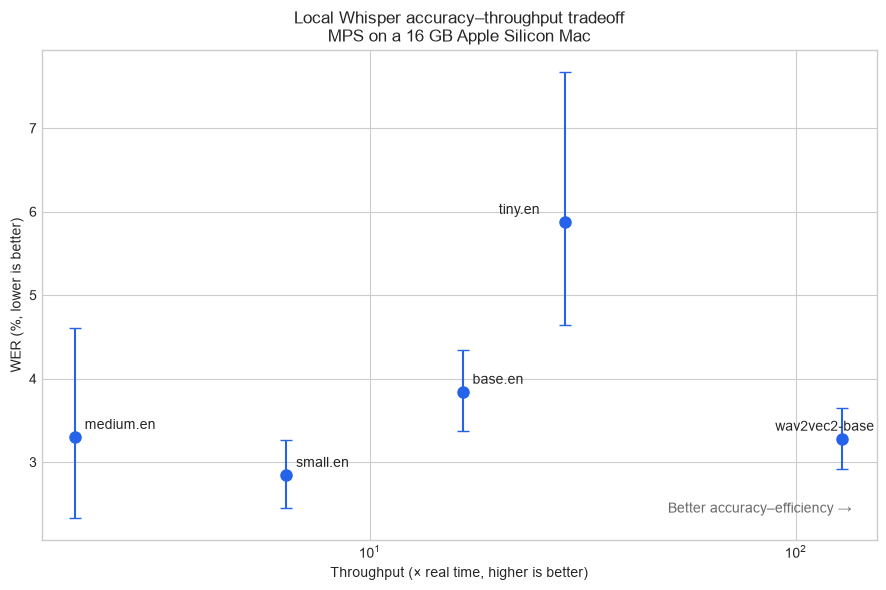

In [10]:
plot_df = combined_results.copy()
lower_error = plot_df['Full-test WER (%)'] - plot_df['CI lower (%)']
upper_error = plot_df['CI upper (%)'] - plot_df['Full-test WER (%)']
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(plot_df['throughput_x'], plot_df['Full-test WER (%)'], yerr=[lower_error, upper_error],
            fmt='o', markersize=8, capsize=4, color='#2563eb')
for _, row in plot_df.iterrows():
    offset = (-48, 6) if row['model'] in ['tiny.en', 'wav2vec2-base'] else (7, 6)
    ax.annotate(row['model'], (row['throughput_x'], row['Full-test WER (%)']),
                xytext=offset, textcoords='offset points')
ax.set_xscale('log')
ax.set_xlim(1.7, 155)
ax.set_xlabel('Throughput (× real time, higher is better)')
ax.set_ylabel('WER (%, lower is better)')
ax.set_title('Local Whisper accuracy–throughput tradeoff\nMPS on a 16 GB Apple Silicon Mac')
ax.text(0.97, 0.05, 'Better accuracy–efficiency →', transform=ax.transAxes,
        ha='right', va='bottom', color='dimgray')
plt.tight_layout()
plt.show()

Wav2Vec2 was the fastest model, processing more than 100 seconds of audio per second. Small was more accurate on clean speech but processed about 6 seconds of audio per second. These results are specific to this 16 GB Mac and are only approximate because the Whisper benchmark generated timestamps while Wav2Vec2 did not. The memory values show MPS memory allocated after warm-up, not the model’s peak total memory use.

## 6. Performance by utterance characteristics

Duration labels and the word-count and words-per-second cut points come from the full test-clean distribution. Each score is corpus WER within the slice, not an average of per-utterance WER.

In [11]:
full_metadata = pd.read_csv(PROJECT_ROOT / 'data' / 'librispeech_test_clean_metadata.csv',
                            dtype={'sample_id': str, 'speaker_id': str})
full_metadata['reference_words'] = full_metadata['reference'].fillna('').map(normalizer).str.split().str.len()
full_metadata['words_per_second'] = full_metadata['reference_words'] / full_metadata['duration_sec']
duration_thresholds = full_metadata['duration_sec'].quantile([1 / 3, 2 / 3]).tolist()
word_thresholds = full_metadata['reference_words'].quantile([1 / 3, 2 / 3]).tolist()
speech_rate_thresholds = full_metadata['words_per_second'].quantile([1 / 3, 2 / 3]).tolist()
analysis_df = full_metadata.set_index('sample_id').reindex(full_sample_ids).copy()
analysis_df['duration_bucket'] = pd.cut(
    analysis_df['duration_sec'], [-np.inf, *duration_thresholds, np.inf],
    labels=['short', 'medium', 'long'], include_lowest=True)
analysis_df['word_count_bucket'] = pd.cut(
    analysis_df['reference_words'], [-np.inf, *word_thresholds, np.inf],
    labels=['few', 'medium', 'many'], include_lowest=True)
analysis_df['speech_rate_bucket'] = pd.cut(
    analysis_df['words_per_second'], [-np.inf, *speech_rate_thresholds, np.inf],
    labels=['slow', 'typical', 'fast'], include_lowest=True)
for model in FULL_MODEL_ORDER:
    analysis_df[f'{model}_errors'] = full_model_errors[model]
print(f'Duration cut points: {[round(x, 3) for x in duration_thresholds]}')
print(f'Word-count cut points: {word_thresholds}')
print(f'Words/second cut points: {[round(x, 3) for x in speech_rate_thresholds]}')

Duration cut points: [4.315, 7.92]
Word-count cut points: [12.0, 23.0]
Words/second cut points: [2.506, 2.997]


In [12]:
def summarize_wer_by_slice(frame, column, order):
    rows = []
    for bucket in order:
        group = frame[frame[column] == bucket]
        words = group['reference_words'].sum()
        row = {'bucket': bucket, 'utterances': len(group), 'reference words': words}
        row.update({m: 100 * group[f'{m}_errors'].sum() / words for m in FULL_MODEL_ORDER})
        rows.append(row)
    words = frame['reference_words'].sum()
    overall = {'bucket': 'Overall', 'utterances': len(frame), 'reference words': words}
    overall.update({m: 100 * frame[f'{m}_errors'].sum() / words for m in FULL_MODEL_ORDER})
    return pd.DataFrame(rows + [overall])

duration_results = summarize_wer_by_slice(analysis_df, 'duration_bucket', ['short', 'medium', 'long'])
word_count_results = summarize_wer_by_slice(analysis_df, 'word_count_bucket', ['few', 'medium', 'many'])
speech_rate_results = summarize_wer_by_slice(analysis_df, 'speech_rate_bucket', ['slow', 'typical', 'fast'])
for title, table in [('Duration', duration_results), ('Reference word count', word_count_results),
                     ('Words per second', speech_rate_results)]:
    print(title)
    display(table.style.hide(axis='index').format({m: '{:.2f}' for m in FULL_MODEL_ORDER}))

# Stability check: repeat the slow-versus-fast comparison with broader 25/75% cutoffs.
q25, q75 = full_metadata['words_per_second'].quantile([0.25, 0.75])
analysis_df['speech_rate_wide'] = pd.cut(
    analysis_df['words_per_second'], [-np.inf, q25, q75, np.inf],
    labels=['slow', 'middle 50%', 'fast'], include_lowest=True)
stability_rows = []
for model in FULL_MODEL_ORDER:
    rates = {}
    for bucket in ['slow', 'fast']:
        group = analysis_df[analysis_df['speech_rate_wide'] == bucket]
        rates[bucket] = 100 * group[f'{model}_errors'].sum() / group['reference_words'].sum()
    stability_rows.append({'model': model, 'slow WER (%)': rates['slow'],
                           'fast WER (%)': rates['fast'],
                           'slow − fast (pp)': rates['slow'] - rates['fast']})
slice_stability = pd.DataFrame(stability_rows)
display(slice_stability.style.hide(axis='index').format({
    'slow WER (%)': '{:.2f}', 'fast WER (%)': '{:.2f}', 'slow − fast (pp)': '{:+.2f}'
}))

Duration


bucket,utterances,reference words,tiny.en,base.en,wav2vec2-base,small.en,medium.en
short,874,7456,6.95,5.11,3.93,3.93,3.53
medium,874,14675,5.49,3.99,3.16,2.79,4.31
long,872,30896,5.79,3.46,3.17,2.61,2.76
Overall,2620,53027,5.87,3.84,3.28,2.84,3.30


Reference word count


bucket,utterances,reference words,tiny.en,base.en,wav2vec2-base,small.en,medium.en
few,931,7699,8.04,5.73,4.35,4.30,3.75
medium,878,15360,5.31,3.89,3.19,2.83,4.55
many,811,29968,5.61,3.32,3.04,2.48,2.54
Overall,2620,53027,5.87,3.84,3.28,2.84,3.30


Words per second


bucket,utterances,reference words,tiny.en,base.en,wav2vec2-base,small.en,medium.en
slow,874,14285,6.57,4.91,4.22,3.82,5.15
typical,873,20277,6.66,3.62,3.03,2.51,2.67
fast,873,18465,4.46,3.25,2.81,2.45,2.55
Overall,2620,53027,5.87,3.84,3.28,2.84,3.30


model,slow WER (%),fast WER (%),slow − fast (pp)
tiny.en,7.18,4.46,+2.72
base.en,5.26,3.15,+2.11
wav2vec2-base,4.78,2.52,+2.27
small.en,4.23,2.30,+1.93
medium.en,6.22,2.55,+3.66


Short and low-word-count utterances have higher WER across models; one error has a larger proportional effect when few words are available, and shorter clips offer less context. Medium performs best in the short and medium duration slices, while small performs best on long and high-word-count recordings. Duration and word count are correlated, so these are descriptive slices, not independent causal effects.

## 7. Speaker sensitivity and qualitative errors

Raw error-count differences show how each speaker contributes to global corpus WER. Individual speaker WER is noisier because speakers contribute 3–16 sampled utterances.

Medium fewer errors: 29; ties: 0; medium more errors: 11


speaker_id,utterances,reference_words,tiny.en_errors,tiny.en_wer,base.en_errors,base.en_wer,small.en_errors,small.en_wer,medium.en_errors,medium.en_wer,medium_minus_small_errors,medium_minus_small_wer_pp
4446,108,1576,66,4.19,48,3.05,34,2.16,319,20.24,285,+18.08
908,57,1101,91,8.27,75,6.81,57,5.18,156,14.17,99,+8.99
7021,59,1201,43,3.58,41,3.41,26,2.16,94,7.83,68,+5.66
8455,71,1377,88,6.39,64,4.65,41,2.98,59,4.28,18,+1.31
5142,102,1676,98,5.85,69,4.12,54,3.22,63,3.76,9,+0.54
1995,72,1288,61,4.74,40,3.11,24,1.86,31,2.41,7,+0.54
5639,42,1471,100,6.80,70,4.76,45,3.06,51,3.47,6,+0.41
8224,32,1025,34,3.32,28,2.73,18,1.76,24,2.34,6,+0.59
260,82,1291,55,4.26,35,2.71,26,2.01,31,2.40,5,+0.39
1188,45,1304,41,3.14,27,2.07,17,1.30,20,1.53,3,+0.23


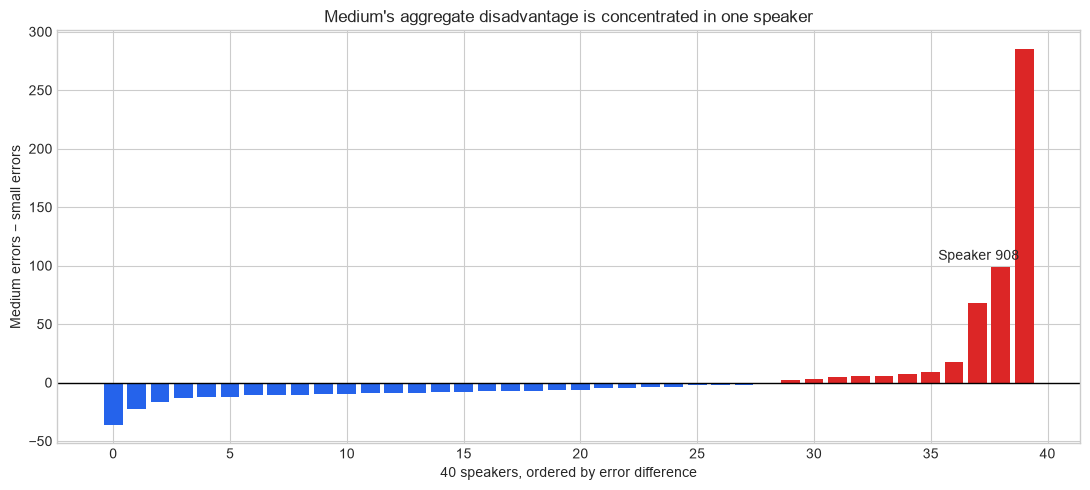

sample_id,medium − small errors,reference,small.en,medium.en
908-157963-0000,10,TO FADE AWAY LIKE MORNING BEAUTY FROM HER MORTAL DAY DOWN BY THE RIVER OF ADONA HER SOFT VOICE IS HEARD AND THUS HER GENTLE LAMENTATION FALLS LIKE MORNING DEW,"to fade away like morning beauty from her mortal day, down by the river of Adana her soft voice is heard, and thus her gentle lamentation falls like morning dew.","Down by the river of Adana her soft voice is heard, And thus her gentle lamentation falls like morning dew."
908-31957-0019,7,THOU CANST WAIT THROUGH SORROW AND SICKNESS TO BRING SOULS TO TOUCH AND THINK IT SOON WHEN OTHERS CRY TOO LATE,"Thou canst wait, through sorrow and sickness, to bring souls to touch, and think it soon when others cry too late.","To bring souls to touch, And think it soon when others cry too late."
908-157963-0021,5,LIVES NOT ALONE NOR OR ITSELF FEAR NOT AND I WILL CALL THE WEAK WORM FROM ITS LOWLY BED AND THOU SHALT HEAR ITS VOICE,"Lives not alone, nor of itself. Fear not, and I will call. The weak worm from its lowly bed, And thou shalt hear its voice.","Fear not, and I will call, The weak worm from its lowly bed, And thou shalt hear its voice."


In [13]:
speaker_rows = []
for speaker_id, group in analysis_df.groupby('speaker_id'):
    words = group['reference_words'].sum()
    row = {'speaker_id': speaker_id, 'utterances': len(group), 'reference_words': words}
    for model in MODEL_ORDER:
        errors = group[f'{model}_errors'].sum()
        row[f'{model}_errors'] = errors
        row[f'{model}_wer'] = 100 * errors / words
    speaker_rows.append(row)
speaker_results = pd.DataFrame(speaker_rows)
speaker_results['medium_minus_small_errors'] = (
    speaker_results['medium.en_errors'] - speaker_results['small.en_errors'])
speaker_results['medium_minus_small_wer_pp'] = (
    speaker_results['medium.en_wer'] - speaker_results['small.en_wer'])
medium_better = (speaker_results['medium_minus_small_errors'] < 0).sum()
ties = (speaker_results['medium_minus_small_errors'] == 0).sum()
medium_worse = (speaker_results['medium_minus_small_errors'] > 0).sum()
print(f'Medium fewer errors: {medium_better}; ties: {ties}; medium more errors: {medium_worse}')
display(speaker_results.sort_values('medium_minus_small_errors', ascending=False).head(10)
        .style.hide(axis='index').format({
            'tiny.en_wer': '{:.2f}', 'base.en_wer': '{:.2f}',
            'small.en_wer': '{:.2f}', 'medium.en_wer': '{:.2f}',
            'medium_minus_small_wer_pp': '{:+.2f}'}))

speaker_plot = speaker_results.sort_values('medium_minus_small_errors').reset_index(drop=True)
colors = np.where(speaker_plot['medium_minus_small_errors'] > 0, '#dc2626', '#2563eb')
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(len(speaker_plot)), speaker_plot['medium_minus_small_errors'], color=colors)
ax.axhline(0, color='black', linewidth=1)
outlier_position = speaker_plot.index[speaker_plot['speaker_id'] == '908'][0]
ax.annotate('Speaker 908',
            (outlier_position, speaker_plot.loc[outlier_position, 'medium_minus_small_errors']),
            xytext=(-45, 5), textcoords='offset points')
ax.set_xlabel('40 speakers, ordered by error difference')
ax.set_ylabel('Medium errors − small errors')
ax.set_title("Medium's aggregate disadvantage is concentrated in one speaker")
plt.tight_layout()
plt.show()

example_ids = ['908-157963-0000', '908-31957-0019', '908-157963-0021']
example_rows = []
for sample_id in example_ids:
    position = sample_ids.get_loc(sample_id)
    example_rows.append({
        'sample_id': sample_id,
        'medium − small errors': int(model_errors['medium.en'][position] - model_errors['small.en'][position]),
        'reference': frames['tiny.en'].loc[sample_id, 'reference'],
        'small.en': frames['small.en'].loc[sample_id, 'prediction'],
        'medium.en': frames['medium.en'].loc[sample_id, 'prediction'],
    })
display(pd.DataFrame(example_rows).style.hide(axis='index'))

In [14]:
speaker_908_full = speaker_results.loc[speaker_results['speaker_id'] == '908', [
    'speaker_id', 'utterances', 'reference_words', 'small.en_errors', 'small.en_wer',
    'medium.en_errors', 'medium.en_wer', 'medium_minus_small_errors',
    'medium_minus_small_wer_pp',
]]
display(speaker_908_full.style.hide(axis='index').format({
    'small.en_wer': '{:.2f}', 'medium.en_wer': '{:.2f}',
    'medium_minus_small_wer_pp': '{:+.2f}',
}))

speaker_id,utterances,reference_words,small.en_errors,small.en_wer,medium.en_errors,medium.en_wer,medium_minus_small_errors,medium_minus_small_wer_pp
908,57,1101,57,5.18,156,14.17,99,+8.99


On the complete test set, Medium makes fewer errors than Small for 29 speakers and more errors for 11. Its disadvantage is concentrated in three readers, especially speakers 4446, 908, and 7021. Speaker 908 remains a problem rather than disappearing with more data: across 57 recordings, Small has 5.18% WER and Medium has 14.17%. Manual listening confirmed that the sampled omitted opening clauses are clearly audible and correctly referenced. The targeted decoding check below shows that these omissions persist when timestamps are disabled on short clips, while several extreme repeated insertions disappear.

## 8. Looking past WER: long-span omission and hallucination

WER counts individual words but does not distinguish scattered mistakes from a missing clause or a long hallucinated continuation. For a captioning product owner choosing the default model for an auto-publish workflow, either failure may require human review even when average WER is low. The full-test analysis therefore reports contiguous deletion spans, leading deletions, and long insertion spans. These are exploratory operational diagnostics, not established standards.

In [15]:
full_risk_rows = []
for model in FULL_MODEL_ORDER:
    components = full_components[model]
    deletion_spans = components['maximum_deletion_span']
    insertion_spans = components['maximum_insertion_span']
    leading_spans = components['leading_deletion_span']
    severe_outputs = (deletion_spans >= 3) | (insertion_spans >= 3)
    full_risk_rows.append({
        'model': model,
        'severe-output utterances': int(severe_outputs.sum()),
        'severe-output rate (%)': 100 * severe_outputs.mean(),
        'deletion rate (%)': 100 * components['deletions'].sum() / full_reference_words.sum(),
        'insertion rate (%)': 100 * components['insertions'].sum() / full_reference_words.sum(),
        'leading-deletion utterances': int((leading_spans > 0).sum()),
        'utterances with ≥3-word consecutive omission': int((deletion_spans >= 3).sum()),
        'longest consecutive omission': int(deletion_spans.max()),
        'utterances with ≥3-word consecutive insertion': int((insertion_spans >= 3).sum()),
        'longest consecutive insertion': int(insertion_spans.max()),
    })
full_risk_summary = pd.DataFrame(full_risk_rows)
display(full_risk_summary.style.hide(axis='index').format({
    'severe-output rate (%)': '{:.2f}',
    'deletion rate (%)': '{:.2f}', 'insertion rate (%)': '{:.2f}',
}))

hallucination_examples = []
for model in FULL_MODEL_ORDER:
    spans = full_components[model]['maximum_insertion_span']
    if spans.max() >= 10:
        position = int(np.argmax(spans))
        sample_id = full_sample_ids[position]
        hallucination_examples.append({
            'model': model, 'sample_id': sample_id,
            'maximum insertion span': int(spans[position]),
            'reference': full_frames[model].iloc[position]['reference'],
            'prediction excerpt': str(full_frames[model].iloc[position]['prediction'])[:500],
        })
display(pd.DataFrame(hallucination_examples).style.hide(axis='index'))

# Re-decode the union of flagged Whisper recordings without timestamps for clips <=30 s.
# Whisper technically requires timestamp tokens for long-form audio, so two >30 s clips use them.
timestamp_sensitivity_rows = []
for model in MODEL_ORDER:
    alternate = pd.read_csv(
        RESULTS_DIR / f'openai_whisper-{model}_librispeech_flagged_auto_timestamps.csv',
        dtype={'sample_id': str},
    ).fillna({'prediction': ''}).set_index('sample_id')
    original_positions = full_sample_ids.get_indexer(alternate.index)
    alternate_errors, alternate_deletion_spans, alternate_insertion_spans = [], [], []
    for sample_id, row in alternate.iterrows():
        alignment = process_words(normalizer(str(row['reference'])), normalizer(str(row['prediction'])))
        chunks = alignment.alignments[0]
        alternate_errors.append(alignment.substitutions + alignment.deletions + alignment.insertions)
        alternate_deletion_spans.append(max(
            [c.ref_end_idx - c.ref_start_idx for c in chunks if c.type == 'delete'], default=0))
        alternate_insertion_spans.append(max(
            [c.hyp_end_idx - c.hyp_start_idx for c in chunks if c.type == 'insert'], default=0))
    alternate_errors = np.asarray(alternate_errors)
    alternate_severe = ((np.asarray(alternate_deletion_spans) >= 3) |
                        (np.asarray(alternate_insertion_spans) >= 3))
    adjusted_errors = (full_model_errors[model].sum()
                       - full_model_errors[model][original_positions].sum()
                       + alternate_errors.sum())
    timestamp_sensitivity_rows.append({
        'model': model,
        'flagged recordings re-decoded': len(alternate),
        'clips decoded without timestamps': int((alternate['duration_sec'] <= 30).sum()),
        'original severe recordings': int(((full_components[model]['maximum_deletion_span'] >= 3) |
                                           (full_components[model]['maximum_insertion_span'] >= 3)).sum()),
        'severe recordings after targeted re-decode': int(alternate_severe.sum()),
        'original full WER (%)': 100 * full_model_errors[model].sum() / full_reference_words.sum(),
        'sensitivity WER (%)': 100 * adjusted_errors / full_reference_words.sum(),
    })
timestamp_sensitivity = pd.DataFrame(timestamp_sensitivity_rows)
display(timestamp_sensitivity.style.hide(axis='index').format({
    'original full WER (%)': '{:.2f}', 'sensitivity WER (%)': '{:.2f}'
}))

model,severe-output utterances,severe-output rate (%),deletion rate (%),insertion rate (%),leading-deletion utterances,utterances with ≥3-word consecutive omission,longest consecutive omission,utterances with ≥3-word consecutive insertion,longest consecutive insertion
tiny.en,8,0.31,0.51,1.50,3,1,3,7,392
base.en,3,0.11,0.41,0.53,3,0,2,3,4
wav2vec2-base,1,0.04,0.38,0.31,3,0,2,1,3
small.en,4,0.15,0.40,0.32,12,1,21,3,12
medium.en,18,0.69,0.52,0.98,23,14,10,4,220


model,sample_id,maximum insertion span,reference,prediction excerpt
tiny.en,3575-170457-0036,392,MY EYES FILL WITH TEARS WHEN I CONTRAST THE BLISS OF SUCH A STATE BRIGHTENED BY HOPES OF THE FUTURE WITH THE MELANCHOLY STATE I NOW LIVE IN UNCERTAIN THAT I EVER FELT TRUE CONTRITION WANDERING IN THOUGHT AND DEED LONGING FOR HOLINESS WHICH I SHALL NEVER NEVER OBTAIN SMITTEN AT TIMES TO THE HEART WITH THE CONVICTION THAT GHASTLY CALVINISTIC DOCTRINES ARE TRUE DARKENED IN SHORT BY THE VERY SHADOWS OF SPIRITUAL DEATH,"My eyes filled tears when I contrast the bliss of such a state, brightened by hopes of the future, with the melancholy state I now live in uncertain that I ever felt true contrition. Wondering, in thought, indeed, longing for holiness, which I shall never, never obtain, smitten at times to the heart. With the conviction that ghastly Calvinistic doctrines are true, darkened in short by the very shadows of spiritual death, Thank you so much for watching, and I'll see you in the next video, and I'"
small.en,672-122797-0038,12,THOUGHT THE FIR TREE AND BELIEVED IT ALL BECAUSE THE MAN WHO TOLD THE STORY WAS SO GOOD LOOKING WELL WELL,"thought the fir-tree, and believed it all, because the man who told the story was so good-looking. Well, well, well, well, well, well, well, well, well, well, well, well, well, well,"
medium.en,4446-2275-0016,220,HILDA WATCHED HIM FROM HER CORNER TREMBLING AND SCARCELY BREATHING DARK SHADOWS GROWING ABOUT HER EYES IT,"Hilda watched him from the corner, trembling and scarcely breathing, dark shadows growing about her eyes. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her face. It was as if she had seen her fac"


model,flagged recordings re-decoded,clips decoded without timestamps,original severe recordings,severe recordings after targeted re-decode,original full WER (%),sensitivity WER (%)
tiny.en,30,28,8,7,5.87,5.12
base.en,30,28,3,1,3.84,3.83
small.en,30,28,4,2,2.84,2.79
medium.en,30,28,18,16,3.30,2.66


The severe-output rate is the percentage of recordings where a model omits or inserts at least three consecutive words. In the original full-run predictions, Medium had the highest rate at 0.69% (18 recordings), while Wav2Vec2 and Base had the lowest rates.

To test whether the decoding settings caused these failures, I reran the 28 flagged recordings shorter than 30 seconds without timestamp generation. The largest Tiny, Small, and Medium errors disappeared, but Medium’s omissions for speaker 908 remained. Because only previously flagged recordings were rerun, this is a diagnostic check, not a new full-test result. A complete rerun with consistent decoding would be needed to update the headline scores.

## 9. Metadata reliability

I first checked that the metadata were connected correctly by comparing saved durations with decoded audio and speaker IDs with recording IDs. I then tested whether derived measurements were stable by comparing raw and normalized word counts and by estimating leading silence with two different thresholds. Strong agreement supports using these features for broad comparisons, but does not make them exact measurements.

In [17]:
sample_analysis_df = pd.read_csv(
    PROJECT_ROOT / 'data' / 'manifest_n300.csv', dtype={'sample_id': str, 'speaker_id': str}
).set_index('sample_id').reindex(sample_ids)
sample_analysis_df['reference_words'] = reference_words
sample_analysis_df['words_per_second'] = (
    sample_analysis_df['reference_words'] / sample_analysis_df['duration_sec'])
sample_analysis_df['speech_rate_bucket'] = pd.cut(
    sample_analysis_df['words_per_second'], [-np.inf, *speech_rate_thresholds, np.inf],
    labels=['slow', 'typical', 'fast'], include_lowest=True)
acoustic = pd.read_csv(PROJECT_ROOT / 'data' / 'acoustic_metadata_n300.csv',
                       dtype={'sample_id': str, 'speaker_id': str})
result_durations = frames['tiny.en']['duration_sec'].reindex(sample_analysis_df.index)
duration_difference = (result_durations - sample_analysis_df['duration_sec']).abs()
acoustic_aligned = acoustic.set_index('sample_id').reindex(sample_analysis_df.index)
decoded_duration_difference = (acoustic_aligned['decoded_duration_sec'] - sample_analysis_df['duration_sec']).abs()
leading_difference = (acoustic_aligned['leading_silence_a_sec'] - acoustic_aligned['leading_silence_b_sec']).abs()
speaker_from_id = sample_analysis_df.index.to_series().str.split('-', n=1).str[0]
speaker_agreement = (speaker_from_id == sample_analysis_df['speaker_id']).mean()
raw_word_count = sample_analysis_df['reference'].fillna('').str.split().str.len()
normalized_word_count = sample_analysis_df['reference_words']
raw_wps = raw_word_count / sample_analysis_df['duration_sec']
normalized_wps = normalized_word_count / sample_analysis_df['duration_sec']
full_raw_word_count = full_metadata['reference'].fillna('').str.split().str.len()
full_raw_wps = full_raw_word_count / full_metadata['duration_sec']
raw_wps_thresholds = full_raw_wps.quantile([1 / 3, 2 / 3]).tolist()
raw_wps_bucket = pd.cut(raw_wps, [-np.inf, *raw_wps_thresholds, np.inf],
                            labels=['slow', 'typical', 'fast'], include_lowest=True)
reliability_summary = pd.DataFrame([
    {'metadata': 'Audio duration', 'test': 'Maximum manifest/result consistency difference',
     'result': f'{duration_difference.max():.6f} seconds'},
    {'metadata': 'Audio duration', 'test': 'Maximum manifest/fresh-decode difference',
     'result': f'{decoded_duration_difference.max():.6f} seconds'},
    {'metadata': 'Leading silence', 'test': 'Two-threshold rank correlation',
     'result': f"{acoustic_aligned['leading_silence_a_sec'].corr(acoustic_aligned['leading_silence_b_sec'], method='spearman'):.4f}"},
    {'metadata': 'Leading silence', 'test': 'Median two-threshold difference',
     'result': f'{leading_difference.median():.3f} seconds'},
    {'metadata': 'Leading silence', 'test': 'Agreement within 50 ms',
     'result': f'{(leading_difference <= 0.05).mean():.1%}'},
    {'metadata': 'Speaker ID', 'test': 'Agreement with sample-ID prefix',
     'result': f'{speaker_agreement:.1%}'},
    {'metadata': 'Reference word count', 'test': 'Raw/normalized rank correlation',
     'result': f"{raw_word_count.corr(normalized_word_count, method='spearman'):.4f}"},
    {'metadata': 'Reference word count', 'test': 'Exact raw/normalized agreement',
     'result': f'{(raw_word_count == normalized_word_count).mean():.1%}'},
    {'metadata': 'Reference word count', 'test': 'Maximum count difference',
     'result': f'{(raw_word_count - normalized_word_count).abs().max()} words'},
    {'metadata': 'Words per second', 'test': 'Raw/normalized rank correlation',
     'result': f"{raw_wps.corr(normalized_wps, method='spearman'):.4f}"},
    {'metadata': 'Words per second', 'test': 'Raw/normalized bucket agreement',
     'result': f"{(raw_wps_bucket == sample_analysis_df['speech_rate_bucket']).mean():.1%}"},
])
reliability_summary.insert(0, 'check type', reliability_summary['metadata'].map({
    'Audio duration': 'integrity', 'Speaker ID': 'integrity',
    'Reference word count': 'text-feature stability',
    'Words per second': 'text-feature stability',
    'Leading silence': 'method agreement',
}))
display(reliability_summary.style.hide(axis='index'))

check type,metadata,test,result
integrity,Audio duration,Maximum manifest/result consistency difference,0.000000 seconds
integrity,Audio duration,Maximum manifest/fresh-decode difference,0.000000 seconds
method agreement,Leading silence,Two-threshold rank correlation,0.8475
method agreement,Leading silence,Median two-threshold difference,0.010 seconds
method agreement,Leading silence,Agreement within 50 ms,84.3%
integrity,Speaker ID,Agreement with sample-ID prefix,100.0%
text-feature stability,Reference word count,Raw/normalized rank correlation,0.9987
text-feature stability,Reference word count,Exact raw/normalized agreement,83.3%
text-feature stability,Reference word count,Maximum count difference,2 words
text-feature stability,Words per second,Raw/normalized rank correlation,0.9877


## 10. Out-of-domain sensitivity: Earnings22

To test whether the LibriSpeech conclusions survive domain shift, the same five models are evaluated on the fixed 300-segment Earnings22 sample characterized in Notebook 01. The sample covers all six source calls and is allocated proportionally within source-call × duration-tertile strata. Earnings22 is conversational financial-call speech rather than clean narrated audiobooks.

Whisper uses ordinary short-form decoding for the 299 clips below 30 seconds and timestamp decoding for the single 30.46-second clip. Wav2Vec2 used its standard transcription settings and did not generate timestamps. The original forced-timestamp Whisper outputs are retained only as a decoding-sensitivity diagnostic because controlled re-decoding showed that timestamp mode triggered runaway repetitions on several short clips.

In [18]:
earnings_result_files = {
    'tiny.en': RESULTS_DIR / 'openai_whisper-tiny.en_earnings22_n300_shortform.csv',
    'base.en': RESULTS_DIR / 'openai_whisper-base.en_earnings22_n300_shortform.csv',
    'wav2vec2-base': RESULTS_DIR / 'facebook_wav2vec2-base-960h_earnings22_n300.csv',
    'small.en': RESULTS_DIR / 'openai_whisper-small.en_earnings22_n300_shortform.csv',
    'medium.en': RESULTS_DIR / 'openai_whisper-medium.en_earnings22_n300_shortform.csv',
}
earnings_manifest_path = PROJECT_ROOT / 'data' / 'earnings22_manifest_n300.csv'
missing_earnings = [p for p in [*earnings_result_files.values(), earnings_manifest_path] if not p.exists()]
if missing_earnings:
    raise FileNotFoundError('Missing Earnings22 files:\n' + '\n'.join(map(str, missing_earnings)))

earnings_frames = {
    model: pd.read_csv(path, dtype={'sample_id': str}).set_index('sample_id')
    for model, path in earnings_result_files.items()
}
earnings_ids = earnings_frames['tiny.en'].index
earnings_base_references = earnings_frames['tiny.en']['reference'].fillna('').reindex(earnings_ids)
for model in FULL_MODEL_ORDER:
    earnings_frames[model] = earnings_frames[model].reindex(earnings_ids)
    earnings_frames[model]['prediction'] = earnings_frames[model]['prediction'].fillna('')
    if len(earnings_frames[model]) != 300 or not earnings_frames[model].index.is_unique:
        raise ValueError(f'{model} Earnings22 result is incomplete')
    if not earnings_frames[model]['reference'].fillna('').equals(earnings_base_references):
        raise ValueError(f'{model} Earnings22 references do not align')

earnings_manifest = (pd.read_csv(earnings_manifest_path, dtype={'sample_id': str, 'source_call_id': str})
                     .set_index('sample_id').reindex(earnings_ids))
earnings_references = [normalizer(str(text)) for text in earnings_base_references]
earnings_reference_words = np.array([len(text.split()) for text in earnings_references])
earnings_calls = earnings_manifest['source_call_id'].to_numpy()
earnings_weights = earnings_manifest['sampling_weight'].to_numpy()

earnings_normalization_rows = []
earnings_components, earnings_model_errors = {}, {}
for model in FULL_MODEL_ORDER:
    raw_predictions = earnings_frames[model]['prediction'].tolist()
    for strategy, transform in normalizers.items():
        earnings_normalization_rows.append({
            'model': model, 'normalization': strategy,
            'WER (%)': 100 * wer(
                [transform(x) for x in earnings_base_references],
                [transform(x) for x in raw_predictions],
            ),
        })
    predictions = [normalizer(str(text)) for text in raw_predictions]
    substitutions, deletions, insertions = [], [], []
    maximum_deletions, maximum_insertions, leading_deletions = [], [], []
    for reference, prediction in zip(earnings_references, predictions):
        alignment = process_words(reference, prediction)
        chunks = alignment.alignments[0]
        substitutions.append(alignment.substitutions)
        deletions.append(alignment.deletions)
        insertions.append(alignment.insertions)
        maximum_deletions.append(max(
            [c.ref_end_idx - c.ref_start_idx for c in chunks if c.type == 'delete'], default=0
        ))
        maximum_insertions.append(max(
            [c.hyp_end_idx - c.hyp_start_idx for c in chunks if c.type == 'insert'], default=0
        ))
        first = chunks[0] if chunks else None
        leading_deletions.append(
            first.ref_end_idx - first.ref_start_idx
            if first is not None and first.type == 'delete' and first.ref_start_idx == 0 else 0
        )
    substitutions, deletions, insertions = map(np.asarray, (substitutions, deletions, insertions))
    earnings_components[model] = {
        'substitutions': substitutions, 'deletions': deletions, 'insertions': insertions,
        'maximum_deletion_span': np.asarray(maximum_deletions),
        'maximum_insertion_span': np.asarray(maximum_insertions),
        'leading_deletion_span': np.asarray(leading_deletions),
    }
    earnings_model_errors[model] = substitutions + deletions + insertions

earnings_normalization_summary = pd.DataFrame(earnings_normalization_rows).pivot(
    index='model', columns='normalization', values='WER (%)'
).reindex(FULL_MODEL_ORDER)
display(earnings_normalization_summary.style.format('{:.2f}'))

normalization,Custom product rules,Lowercase,Lowercase + punctuation,Raw,Whisper Basic,Whisper English
model,,,,,,
tiny.en,23.36,33.18,27.04,35.49,27.04,23.24
base.en,12.94,22.99,16.88,25.08,16.88,12.83
wav2vec2-base,41.84,51.64,43.92,104.83,43.92,42.01
small.en,11.69,21.60,15.66,23.61,15.66,11.45
medium.en,11.30,21.38,15.20,23.36,15.20,11.06


model,LibriSpeech WER (%),Earnings22 WER (%),call-cluster CI lower (%),call-cluster CI upper (%),weighted WER (%),generalization penalty (pp)
tiny.en,5.87,23.24,15.27,34.10,23.21,+17.37
base.en,3.84,12.83,10.20,16.03,12.84,+9.00
wav2vec2-base,3.28,42.01,38.50,48.08,42.03,+38.74
small.en,2.84,11.45,9.41,13.76,11.47,+8.61
medium.en,3.30,11.06,9.04,14.10,11.09,+7.76


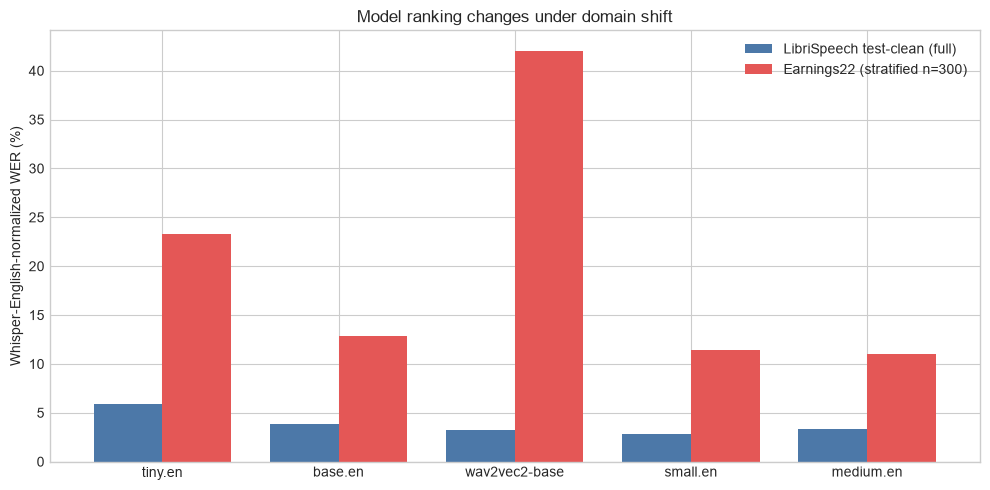

In [19]:
earnings_unique_calls = np.unique(earnings_calls)
earnings_call_words = np.array([
    earnings_reference_words[earnings_calls == call].sum() for call in earnings_unique_calls
])
earnings_call_errors = {
    model: np.array([earnings_model_errors[model][earnings_calls == call].sum()
                     for call in earnings_unique_calls])
    for model in FULL_MODEL_ORDER
}
earnings_rng = np.random.default_rng(SEED)
earnings_call_draws = earnings_rng.integers(
    0, len(earnings_unique_calls), size=(10_000, len(earnings_unique_calls))
)
earnings_bootstrap_words = earnings_call_words[earnings_call_draws].sum(axis=1)
earnings_bootstrap_wer = {
    model: earnings_call_errors[model][earnings_call_draws].sum(axis=1) / earnings_bootstrap_words
    for model in FULL_MODEL_ORDER
}

libri_wer_lookup = full_wer_summary.set_index('model')['Full-test WER (%)']
earnings_wer_rows = []
for model in FULL_MODEL_ORDER:
    point = 100 * earnings_model_errors[model].sum() / earnings_reference_words.sum()
    weighted = 100 * np.sum(earnings_weights * earnings_model_errors[model]) / np.sum(
        earnings_weights * earnings_reference_words
    )
    lower, upper = np.quantile(100 * earnings_bootstrap_wer[model], [0.025, 0.975])
    earnings_wer_rows.append({
        'model': model,
        'LibriSpeech WER (%)': libri_wer_lookup.loc[model],
        'Earnings22 WER (%)': point,
        'call-cluster CI lower (%)': lower,
        'call-cluster CI upper (%)': upper,
        'weighted WER (%)': weighted,
        'generalization penalty (pp)': point - libri_wer_lookup.loc[model],
    })
earnings_wer_summary = pd.DataFrame(earnings_wer_rows)
display(earnings_wer_summary.style.hide(axis='index').format({
    'LibriSpeech WER (%)': '{:.2f}', 'Earnings22 WER (%)': '{:.2f}',
    'call-cluster CI lower (%)': '{:.2f}', 'call-cluster CI upper (%)': '{:.2f}',
    'weighted WER (%)': '{:.2f}', 'generalization penalty (pp)': '{:+.2f}',
}))

plot_data = earnings_wer_summary.set_index('model')[['LibriSpeech WER (%)', 'Earnings22 WER (%)']]
ax = plot_data.plot(kind='bar', figsize=(10, 5), color=['#4C78A8', '#E45756'], width=0.78)
ax.set(title='Model ranking changes under domain shift', xlabel='', ylabel='Whisper-English-normalized WER (%)')
ax.legend(['LibriSpeech test-clean (full)', 'Earnings22 (stratified n=300)'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
earnings_comparison_rows = []
for first, second in zip(FULL_MODEL_ORDER[:-1], FULL_MODEL_ORDER[1:]):
    differences = earnings_bootstrap_wer[first] - earnings_bootstrap_wer[second]
    lower, upper = np.quantile(100 * differences, [0.025, 0.975])
    earnings_comparison_rows.append({
        'comparison': f'{first} → {second}',
        'WER improvement (pp)': 100 * (
            earnings_model_errors[first].sum() - earnings_model_errors[second].sum()
        ) / earnings_reference_words.sum(),
        'CI lower (pp)': lower, 'CI upper (pp)': upper,
        'CI excludes zero?': bool(lower > 0 or upper < 0),
    })
earnings_comparison_summary = pd.DataFrame(earnings_comparison_rows)
display(earnings_comparison_summary.style.hide(axis='index').format({
    'WER improvement (pp)': '{:+.2f}', 'CI lower (pp)': '{:+.2f}', 'CI upper (pp)': '{:+.2f}',
}))

earnings_call_wer = pd.DataFrame({
    model: 100 * earnings_call_errors[model] / earnings_call_words
    for model in FULL_MODEL_ORDER
}, index=earnings_unique_calls)
earnings_call_wer.index.name = 'source_call_id'
display(earnings_call_wer.style.format('{:.2f}').background_gradient(cmap='Reds', axis=None)
        .set_caption('WER (%) by source call; darker is worse'))

comparison,WER improvement (pp),CI lower (pp),CI upper (pp),CI excludes zero?
tiny.en → base.en,+10.41,+2.40,+22.68,True
base.en → wav2vec2-base,-29.18,-32.91,-26.53,True
wav2vec2-base → small.en,+30.56,+27.56,+35.02,True
small.en → medium.en,+0.39,-0.96,+1.41,False


,tiny.en,base.en,wav2vec2-base,small.en,medium.en
source_call_id,,,,,
4432298,28.64,20.44,56.45,16.58,19.10
4450488,12.45,10.74,35.53,10.21,10.85
4470290,19.55,15.10,52.48,11.63,12.62
4479741,16.48,13.97,41.27,13.43,11.46
4483338,16.33,13.70,39.94,11.84,9.98
4485244,42.77,8.14,39.20,7.89,7.56


In [21]:
earnings_risk_rows = []
for model in FULL_MODEL_ORDER:
    components = earnings_components[model]
    severe_outputs = ((components['maximum_deletion_span'] >= 3) |
                      (components['maximum_insertion_span'] >= 3))
    earnings_risk_rows.append({
        'model': model,
        'severe-output utterances': int(severe_outputs.sum()),
        'severe-output rate (%)': 100 * severe_outputs.mean(),
        'deletion rate (%)': 100 * components['deletions'].sum() / earnings_reference_words.sum(),
        'insertion rate (%)': 100 * components['insertions'].sum() / earnings_reference_words.sum(),
        'leading-deletion utterances': int((components['leading_deletion_span'] > 0).sum()),
        '≥3-word consecutive omissions': int((components['maximum_deletion_span'] >= 3).sum()),
        'longest consecutive omission': int(components['maximum_deletion_span'].max()),
        '≥3-word consecutive insertions': int((components['maximum_insertion_span'] >= 3).sum()),
        'longest consecutive insertion': int(components['maximum_insertion_span'].max()),
    })
earnings_risk_summary = pd.DataFrame(earnings_risk_rows)
display(earnings_risk_summary.style.hide(axis='index').format({
    'severe-output rate (%)': '{:.2f}', 'deletion rate (%)': '{:.2f}', 'insertion rate (%)': '{:.2f}',
}))

timestamp_files = {
    model: RESULTS_DIR / f'openai_whisper-{model}_earnings22_n300.csv' for model in MODEL_ORDER
}
timestamp_rows = []
for model in MODEL_ORDER:
    timestamp_frame = pd.read_csv(timestamp_files[model], dtype={'sample_id': str}).set_index('sample_id').reindex(earnings_ids)
    timestamp_predictions = timestamp_frame['prediction'].fillna('').map(normalizer).tolist()
    timestamp_insertions = []
    for reference, prediction in zip(earnings_references, timestamp_predictions):
        chunks = process_words(reference, prediction).alignments[0]
        timestamp_insertions.append(max(
            [c.hyp_end_idx - c.hyp_start_idx for c in chunks if c.type == 'insert'], default=0
        ))
    short_spans = earnings_components[model]['maximum_insertion_span']
    timestamp_rows.append({
        'model': model,
        'forced timestamps WER (%)': 100 * wer(earnings_references, timestamp_predictions),
        'short-form WER (%)': earnings_wer_summary.set_index('model').loc[model, 'Earnings22 WER (%)'],
        'forced timestamps max insertion': max(timestamp_insertions),
        'short-form max insertion': int(short_spans.max()),
        'forced timestamps ≥3-word insertions': int((np.asarray(timestamp_insertions) >= 3).sum()),
        'short-form ≥3-word insertions': int((short_spans >= 3).sum()),
    })
timestamp_sensitivity = pd.DataFrame(timestamp_rows)
display(timestamp_sensitivity.style.hide(axis='index').format({
    'forced timestamps WER (%)': '{:.2f}', 'short-form WER (%)': '{:.2f}',
}))

model,severe-output utterances,severe-output rate (%),deletion rate (%),insertion rate (%),leading-deletion utterances,≥3-word consecutive omissions,longest consecutive omission,≥3-word consecutive insertions,longest consecutive insertion
tiny.en,30,10.00,4.43,10.89,7,17,9,14,293
base.en,23,7.67,4.39,2.69,9,15,9,10,5
wav2vec2-base,39,13.00,6.02,9.28,16,20,7,20,7
small.en,27,9.00,4.65,2.17,9,20,12,9,3
medium.en,27,9.00,4.75,2.13,9,21,9,8,3


model,forced timestamps WER (%),short-form WER (%),forced timestamps max insertion,short-form max insertion,forced timestamps ≥3-word insertions,short-form ≥3-word insertions
tiny.en,46.81,23.24,730,293,25,14
base.en,30.36,12.83,334,5,17,10
small.en,27.83,11.45,337,3,14,9
medium.en,17.37,11.06,182,3,12,8


Forcing timestamps on short Earnings22 recordings caused many repeated phrases and greatly inflated WER. Short-form decoding produced much more reliable results, although Tiny still generated one very long repetition.

### Comparison with archived public Earnings22 results

The current Open ASR Leaderboard uses a cleaned, call-level scoring condition and no longer displays all five checkpoints. The model cards retain the original 2022 `earnings22_wer` artifacts for the exact checkpoints evaluated here: [tiny.en](https://huggingface.co/openai/whisper-tiny.en/blob/refs%2Fpr%2F27/.eval_results/open_asr_leaderboard.yaml), [base.en](https://huggingface.co/openai/whisper-base.en/discussions/18/files), [small.en](https://huggingface.co/openai/whisper-small.en/blob/9dcb3056ddba3fcf664920f68cf3ebd264d811cf/.eval_results/open_asr_leaderboard.yaml), [medium.en](https://huggingface.co/openai/whisper-medium.en/blob/refs%2Fpr%2F19/.eval_results/open_asr_leaderboard.yaml), and [Wav2Vec2 Base](https://huggingface.co/facebook/wav2vec2-base-960h). These legacy scores are the appropriate published reference, but not an execution-identical target: they use the full evaluation, and their exact decoding and normalization settings are incompletely documented.


In [22]:
published_earnings22_wer = {
    'tiny.en': 19.12,
    'base.en': 15.09,
    'wav2vec2-base': 48.47,
    'small.en': 12.97,
    'medium.en': 12.63,
}
earnings_public_comparison = earnings_wer_summary[[
    'model', 'Earnings22 WER (%)'
]].copy()
earnings_public_comparison['Published full Earnings22 WER (%)'] = (
    earnings_public_comparison['model'].map(published_earnings22_wer)
)
earnings_public_comparison['Local − published (pp)'] = (
    earnings_public_comparison['Earnings22 WER (%)']
    - earnings_public_comparison['Published full Earnings22 WER (%)']
)
earnings_public_comparison['Local rank'] = (
    earnings_public_comparison['Earnings22 WER (%)'].rank(method='min').astype(int)
)
earnings_public_comparison['Published rank'] = (
    earnings_public_comparison['Published full Earnings22 WER (%)']
    .rank(method='min').astype(int)
)
display(earnings_public_comparison.style.hide(axis='index').format({
    'Earnings22 WER (%)': '{:.2f}',
    'Published full Earnings22 WER (%)': '{:.2f}',
    'Local − published (pp)': '{:+.2f}',
}))

rank_match = earnings_public_comparison['Local rank'].equals(
    earnings_public_comparison['Published rank']
)
print(f'Exact five-model ranking reproduced: {rank_match}')

model,Earnings22 WER (%),Published full Earnings22 WER (%),Local − published (pp),Local rank,Published rank
tiny.en,23.24,19.12,+4.12,4,4
base.en,12.83,15.09,-2.26,3,3
wav2vec2-base,42.01,48.47,-6.46,5,5
small.en,11.45,12.97,-1.52,2,2
medium.en,11.06,12.63,-1.57,1,1


Exact five-model ranking reproduced: True


### Qualitative error review and audio playback

Aggregate WER cannot explain why systems differ. The table below creates a deliberate review queue: the largest-error examples for each model, the greatest Wav2Vec2-versus-small gaps, and the strongest small-versus-medium disagreements. It is a diagnostic sample selected because the models fail or disagree—not an unbiased estimate of error prevalence.


In [23]:
earnings_error_review = pd.DataFrame(index=earnings_ids)
earnings_error_review.index.name = 'sample_id'
earnings_error_review['source_call_id'] = earnings_calls
earnings_error_review['duration_sec'] = earnings_manifest['duration_sec'].to_numpy()
earnings_error_review['reference_words'] = earnings_reference_words
for model in FULL_MODEL_ORDER:
    earnings_error_review[f'{model} errors'] = earnings_model_errors[model]
    earnings_error_review[f'{model} deletions'] = earnings_components[model]['deletions']
    earnings_error_review[f'{model} insertions'] = earnings_components[model]['insertions']
earnings_error_review['small − medium errors'] = (
    earnings_error_review['small.en errors'] - earnings_error_review['medium.en errors']
)
earnings_error_review['wav2vec2 − small errors'] = (
    earnings_error_review['wav2vec2-base errors'] - earnings_error_review['small.en errors']
)

candidate_reasons = {}
def add_review_candidates(series, n, reason, absolute=False):
    ranking = series.abs() if absolute else series
    for sample_id in ranking.nlargest(n).index:
        candidate_reasons.setdefault(sample_id, []).append(reason)

for model in FULL_MODEL_ORDER:
    add_review_candidates(earnings_error_review[f'{model} errors'], 2, f'{model}: high error count')
add_review_candidates(earnings_error_review['wav2vec2 − small errors'], 5, 'large Wav2Vec2–small gap')
add_review_candidates(earnings_error_review['small − medium errors'], 5, 'small–medium disagreement', absolute=True)

review_candidates = earnings_error_review.loc[list(candidate_reasons)].reset_index()
review_candidates.insert(1, 'selection reason', [
    '; '.join(candidate_reasons[sample_id]) for sample_id in review_candidates['sample_id']
])
review_columns = [
    'sample_id', 'selection reason', 'source_call_id', 'duration_sec', 'reference_words',
    *[f'{model} errors' for model in FULL_MODEL_ORDER],
    'small − medium errors', 'wav2vec2 − small errors',
]
display(review_candidates[review_columns].style.hide(axis='index').format({
    'duration_sec': '{:.2f}',
}))

sample_id,selection reason,source_call_id,duration_sec,reference_words,tiny.en errors,base.en errors,wav2vec2-base errors,small.en errors,medium.en errors,small − medium errors,wav2vec2 − small errors
4485244/600.wav,tiny.en: high error count,4485244,2.38,5,298,1,4,1,1,0,3
4485244/188.wav,tiny.en: high error count,4485244,4.40,15,97,0,6,0,1,-1,6
4432298/160.wav,base.en: high error count; wav2vec2-base: high error count; small.en: high error count; medium.en: high error count; large Wav2Vec2–small gap,4432298,21.80,54,17,17,36,13,13,0,23
4483338/595.wav,base.en: high error count,4483338,13.52,36,12,16,23,9,11,-2,14
4479741/243.wav,wav2vec2-base: high error count; large Wav2Vec2–small gap,4479741,19.62,48,6,5,26,6,6,0,20
4483338/566.wav,small.en: high error count; small–medium disagreement,4483338,6.80,14,7,7,8,14,7,7,-6
4450488/430.wav,medium.en: high error count; small–medium disagreement,4450488,11.42,15,2,3,9,4,14,-10,5
4485244/42.wav,large Wav2Vec2–small gap,4485244,21.96,44,4,2,24,3,1,2,21
4470290/110.wav,large Wav2Vec2–small gap,4470290,16.02,32,8,5,21,4,4,0,17
4483338/335.wav,large Wav2Vec2–small gap,4483338,15.38,48,5,3,19,2,3,-1,17


In [24]:
from IPython.display import Audio as IPythonAudio, Markdown
from datasets import load_dataset

_earnings_audio_dataset = None
_earnings_audio_row_by_id = None
_earnings_audio_cache = {}

def _load_earnings_audio(sample_id):
    """Decode only the selected recording; reuse the local dataset cache."""
    global _earnings_audio_dataset, _earnings_audio_row_by_id
    if sample_id in _earnings_audio_cache:
        return _earnings_audio_cache[sample_id]
    if _earnings_audio_dataset is None:
        _earnings_audio_dataset = load_dataset(
            'hf-audio/open-asr-leaderboard', 'earnings22', split='test'
        )
        _earnings_audio_row_by_id = {
            str(value): i for i, value in enumerate(_earnings_audio_dataset['id'])
        }
    if sample_id not in _earnings_audio_row_by_id:
        raise KeyError(f'Unknown Earnings22 sample ID: {sample_id}')
    decoded = _earnings_audio_dataset[_earnings_audio_row_by_id[sample_id]]['audio'].get_all_samples()
    waveform = decoded.data
    if waveform.ndim == 2:
        waveform = waveform.mean(dim=0)
    _earnings_audio_cache[sample_id] = (waveform.numpy(), decoded.sample_rate)
    return _earnings_audio_cache[sample_id]

def show_earnings_example(sample_id, max_chars=500, play_audio=True):
    """Show aligned error counts and transcripts, then play one selected clip."""
    sample_id = str(sample_id)
    if sample_id not in earnings_error_review.index:
        raise KeyError(f'{sample_id} is not in the n=300 manifest')
    i = earnings_ids.get_loc(sample_id)
    metadata = earnings_error_review.loc[sample_id]
    display(Markdown(
        f'#### `{sample_id}` — call {metadata.source_call_id}, '
        f'{metadata.duration_sec:.2f} seconds, {metadata.reference_words:.0f} reference words'
    ))
    reference_text = earnings_base_references.loc[sample_id]
    rows = [{'system': 'REFERENCE', 'substitutions': '', 'deletions': '',
             'insertions': '', 'raw transcript': reference_text,
             'normalized transcript': normalizer(reference_text)}]
    for model in FULL_MODEL_ORDER:
        text = earnings_frames[model].loc[sample_id, 'prediction']
        if max_chars is not None and len(text) > max_chars:
            text = text[:max_chars] + ' … [truncated; pass max_chars=None to show all]'
        rows.append({
            'system': model,
            'substitutions': int(earnings_components[model]['substitutions'][i]),
            'deletions': int(earnings_components[model]['deletions'][i]),
            'insertions': int(earnings_components[model]['insertions'][i]),
            'raw transcript': text,
            'normalized transcript': normalizer(earnings_frames[model].loc[sample_id, 'prediction']),
        })
    display(pd.DataFrame(rows).style.hide(axis='index').set_properties(
        subset=['raw transcript', 'normalized transcript'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    ))
    if play_audio:
        waveform, sample_rate = _load_earnings_audio(sample_id)
        display(IPythonAudio(waveform, rate=sample_rate))

print('Run show_earnings_example(sample_id) with an ID from review_candidates to inspect and listen.')
print('Example:', review_candidates.iloc[0]['sample_id'])

Run show_earnings_example(sample_id) with an ID from review_candidates to inspect and listen.
Example: 4485244/600.wav


In [25]:
# Choose any ID from the review table, remove the leading #, and run this cell.
# show_earnings_example(review_candidates.iloc[0]['sample_id'])

# Useful targeted alternatives:
# show_earnings_example('4485244/600.wav', max_chars=None)  # tiny's longest corrected repetition
# show_earnings_example(review_candidates.sort_values('small − medium errors').iloc[0]['sample_id'])
# show_earnings_example(review_candidates.sort_values('small − medium errors').iloc[-1]['sample_id'])

### Reference quality and transcription-policy audit

Listening revealed that not every raw-text disagreement is an ASR failure. Some official references appear inconsistent with the audible speech; some retain disfluencies such as *um* and *uh* that the models omit; and Wav2Vec2 often emits a spoken form where the reference uses written notation (for example, `TWO DOLLARS AND TWENTY THREE CENTS` versus `$2.23`).

The primary Whisper English normalizer removes common fillers and maps written and spoken currency to the same form. The custom product normalizer now handles this currency example, percentages, and ordinals as well. Incorrect reference text is different—it remains label noise under every automatic normalizer and can penalize a correct model.

The observations below summarize the completed qualitative review. They are examples, not prevalence estimates, because the listening queue deliberately emphasized large errors and model disagreements.


In [26]:
normalization_policy_examples = pd.DataFrame([
    {'case': 'currency reference', 'text': '$2.23'},
    {'case': 'currency spoken form', 'text': 'TWO DOLLARS AND TWENTY THREE CENTS'},
    {'case': 'reference with filler', 'text': 'Um, revenue increased'},
    {'case': 'prediction without filler', 'text': 'Revenue increased'},
])
normalization_policy_examples['Whisper English'] = (
    normalization_policy_examples['text'].map(normalizer)
)
normalization_policy_examples['Custom product rules'] = (
    normalization_policy_examples['text'].map(normalize_custom)
)
display(normalization_policy_examples.style.hide(axis='index'))

case,text,Whisper English,Custom product rules
currency reference,$2.23,$2.23,two dollars and twenty three cents
currency spoken form,TWO DOLLARS AND TWENTY THREE CENTS,$2.23,two dollars and twenty three cents
reference with filler,"Um, revenue increased",revenue increased,revenue increased
prediction without filler,Revenue increased,revenue increased,revenue increased


In [27]:
qualitative_findings = pd.DataFrame([
    {'finding': 'Reference disagreement',
     'observed example': 'The audible speech did not always match the supplied reference.',
     'implication': 'Human review is needed before using small score differences for a decision.'},
    {'finding': 'Disfluency policy',
     'observed example': 'References sometimes retain um/uh while model outputs omit them.',
     'implication': 'Part of measured WER reflects transcription policy rather than intelligibility.'},
    {'finding': 'Spoken versus written form',
     'observed example': 'Wav2Vec2 produced TWO DOLLARS AND TWENTY THREE CENTS for $2.23.',
     'implication': 'Normalization must make equivalent semantic forms comparable.'},
])
display(qualitative_findings.style.hide(axis='index'))

finding,observed example,implication
Reference disagreement,The audible speech did not always match the supplied reference.,Human review is needed before using small score differences for a decision.
Disfluency policy,References sometimes retain um/uh while model outputs omit them.,Part of measured WER reflects transcription policy rather than intelligibility.
Spoken versus written form,Wav2Vec2 produced TWO DOLLARS AND TWENTY THREE CENTS for $2.23.,Normalization must make equivalent semantic forms comparable.


### Secondary sensitivity check

For completeness, the table below caps each recording's contribution at twice its reference length. This post-hoc cap is not the added metric and is not used for model selection; it only checks whether a corpus score is being driven by a very small number of runaway outputs.

In [28]:
def capped_corpus_wer(errors, reference_word_counts, cap):
    errors = np.asarray(errors)
    reference_word_counts = np.asarray(reference_word_counts)
    return 100 * np.minimum(errors, cap * reference_word_counts).sum() / reference_word_counts.sum()

cwer_rows = []
for dataset_name, word_counts, error_lookup in [
    ('LibriSpeech full', full_reference_words, full_model_errors),
    ('Earnings22 n=300', earnings_reference_words, earnings_model_errors),
]:
    for model in FULL_MODEL_ORDER:
        errors = error_lookup[model]
        standard = 100 * errors.sum() / word_counts.sum()
        capped = capped_corpus_wer(errors, word_counts, 2)
        cwer_rows.append({'dataset': dataset_name, 'model': model,
                          'standard WER (%)': standard,
                          'capped sensitivity WER (%)': capped,
                          'difference (pp)': standard - capped})
cwer_summary = pd.DataFrame(cwer_rows)
display(cwer_summary.style.hide(axis='index').format({
    'standard WER (%)': '{:.2f}', 'capped sensitivity WER (%)': '{:.2f}',
    'difference (pp)': '{:.2f}',
}))

dataset,model,standard WER (%),capped sensitivity WER (%),difference (pp)
LibriSpeech full,tiny.en,5.87,5.40,0.47
LibriSpeech full,base.en,3.84,3.84,0.00
LibriSpeech full,wav2vec2-base,3.28,3.28,0.00
LibriSpeech full,small.en,2.84,2.84,0.00
LibriSpeech full,medium.en,3.30,2.86,0.43
Earnings22 n=300,tiny.en,23.24,16.51,6.73
Earnings22 n=300,base.en,12.83,12.72,0.11
Earnings22 n=300,wav2vec2-base,42.01,42.00,0.02
Earnings22 n=300,small.en,11.45,11.43,0.02
Earnings22 n=300,medium.en,11.06,11.06,0.00


As a sensitivity check, capping each recording’s contribution reduced Tiny’s Earnings22 WER substantially, while Wav2Vec2’s score barely changed, showing that Tiny’s result was more affected by rare repetitions and Wav2Vec2’s errors were more widespread.

#### Listen to affected LibriSpeech examples

The Earnings22 helper above only searches that dataset. `show_librispeech_example` provides the same raw/normalized transcript comparison and audio control for any ID in the full LibriSpeech test-clean results. Dataset metadata are loaded once; only the selected waveform is decoded and then cached in memory.


In [30]:
_librispeech_audio_cache = {}

def _load_librispeech_audio(sample_id):
    """Decode only the selected LibriSpeech recording and cache it."""
    if sample_id in _librispeech_audio_cache:
        return _librispeech_audio_cache[sample_id]
    stream = load_dataset(
        'openslr/librispeech_asr', 'clean', split='test', streaming=True
    )
    selected = next(
        (sample for sample in stream if str(sample['id']) == sample_id), None
    )
    if selected is None:
        raise KeyError(f'Unknown LibriSpeech test-clean sample ID: {sample_id}')
    decoded = selected['audio'].get_all_samples()
    waveform = decoded.data
    if waveform.ndim == 2:
        waveform = waveform.mean(dim=0)
    _librispeech_audio_cache[sample_id] = (waveform.numpy(), decoded.sample_rate)
    return _librispeech_audio_cache[sample_id]

def show_librispeech_example(sample_id, max_chars=500, play_audio=True):
    """Show all model transcripts and play one LibriSpeech test-clean clip."""
    sample_id = str(sample_id)
    if sample_id not in full_sample_ids:
        raise KeyError(f'{sample_id} is not in the full LibriSpeech results')
    position = full_sample_ids.get_loc(sample_id)
    reference_text = full_base_references.loc[sample_id]
    display(Markdown(
        f'#### `{sample_id}` — '
        f'{full_frames["tiny.en"].loc[sample_id, "duration_sec"]:.2f} seconds, '
        f'{full_reference_words[position]} normalized reference words'
    ))
    rows = [{
        'system': 'REFERENCE', 'substitutions': '', 'deletions': '', 'insertions': '',
        'raw transcript': reference_text, 'normalized transcript': normalizer(reference_text),
    }]
    for model in FULL_MODEL_ORDER:
        raw_text = str(full_frames[model].loc[sample_id, 'prediction'])
        shown_text = raw_text
        if max_chars is not None and len(shown_text) > max_chars:
            shown_text = shown_text[:max_chars] + ' … [truncated; pass max_chars=None to show all]'
        rows.append({
            'system': model,
            'substitutions': int(full_components[model]['substitutions'][position]),
            'deletions': int(full_components[model]['deletions'][position]),
            'insertions': int(full_components[model]['insertions'][position]),
            'raw transcript': shown_text,
            'normalized transcript': normalizer(raw_text),
        })
    display(pd.DataFrame(rows).style.hide(axis='index').set_properties(
        subset=['raw transcript', 'normalized transcript'],
        **{'text-align': 'left', 'white-space': 'pre-wrap'}
    ))
    if play_audio:
        waveform, sample_rate = _load_librispeech_audio(sample_id)
        display(IPythonAudio(waveform, rate=sample_rate))

print('Run show_librispeech_example(sample_id) for any full test-clean ID.')

Run show_librispeech_example(sample_id) for any full test-clean ID.


In [31]:
# Remove the leading # and run one example at a time.
# show_librispeech_example('3575-170457-0036', max_chars=None)  # tiny: 392-word insertion span
# show_librispeech_example('4446-2275-0016', max_chars=None)    # medium: 220-word insertion span
# show_librispeech_example('908-157963-0000')                  # medium: audible opening omission
# show_librispeech_example('908-31957-0019')                   # boundary-sensitive opening omission


### Interpretation

The LibriSpeech ranking does not carry over to Earnings22. Wav2Vec2 rises from 3.28% WER on LibriSpeech to 42.01% on Earnings22. Medium has the lowest Earnings22 WER at 11.06%, narrowly ahead of Small at 11.45%, but the difference is not conclusive across only six source calls.

The sample produces the same five-model ranking as the published full-set results, and weighting changes WER by no more than 0.15 points. This suggests that the sample composition is not driving the ranking, but 300 recordings from six calls cannot reproduce the complete benchmark or support conclusions about individual speakers.

Forcing timestamps on short Whisper recordings caused repeated phrases and substantially increased WER, so the final Earnings22 results use short-form decoding. Listening also found some incorrect references and transcription-policy differences. The small Medium–Small gap should therefore not drive a model choice without a broader reference review.

## 11. Conclusions and limitations

### Deployment recommendation

The recommendation is domain-dependent. On the saved full LibriSpeech run, **small.en has the lowest WER** at 2.84%, while **Wav2Vec2 Base is the efficiency choice** at 3.28% and more than 100× real time. On conversational Earnings22, Wav2Vec2 deteriorates to 42.01%, while Medium and Small reach 11.06% and 11.45%. Across these two datasets, Small is the best observed accuracy–cost compromise, but that recommendation is conditional: the Small–Medium gap is unresolved and two datasets do not establish universal performance.

### Limitations

- LibriSpeech is clean, read English speech, while Earnings22 includes only 300 recordings from six calls. Results may not generalize to other audio, domains, or speakers.
- The Small–Medium accuracy difference remains inconclusive. Earnings22 also lacks reliable speaker IDs, so speaker-level and demographic fairness could not be tested.
- The archived results do not document every model and decoding setting. The targeted timestamp check found configuration-related failures but does not replace a complete, consistently decoded rerun.
- Runtime results are specific to this 16 GB Mac, and Wav2Vec2 has an in-domain advantage because it was fine-tuned on LibriSpeech.
- The severe-output metric and derived metadata are useful diagnostics, but their thresholds should be validated on additional data.
- Manual review found some incorrect or inconsistent references, including differences in fillers and spoken versus written forms. These can make WER count a reasonable transcription as an error.